[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/f5_noise_as_a_ruler.ipynb)

# Noise as a ruler

* **Author**: simone.azeglio@gmail.com

* **Goal**: How much does a blurred look at a stimulus tell you about it? The notebook blurs a stimulus with Gaussian noise, builds the best guess of the stimulus from its blurred version (the denoiser) and splits the information that survives the blur over scales.

* **Needs**: a CPU, no data. `pip install multigeom`.

* **Time**: about 5 s.

* **Next**: notebook f6 adds a neuron and asks which stimuli carry its information.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`. Elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 4 μs, sys: 1 μs, total: 5 μs
Wall time: 6.2 μs


### 1.2. Imports

Import the packages, set the figure style and pick the device. Every tensor is float64, so the device is a CUDA GPU when there is one and the CPU otherwise (Apple's `mps` has no float64).

time: 1 sec

In [2]:
%%time

import math

import matplotlib.pyplot as plt
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(torch.float64)
print("device:", device)

# figure style of the Foundations notebooks: 10 pt text, no top or right spines
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

device: cpu
CPU times: user 742 ms, sys: 149 ms, total: 891 ms
Wall time: 1.23 s


### 1.3. Parameters

The stimulus $x$ is one number. Its prior has two narrow bumps of equal weight, centred at $-1$ and $+1$, each a Gaussian with standard deviation 0.1:

$$p(x) = \tfrac{1}{2}\,\mathcal{N}(x;\,-1,\,0.1^2) + \tfrac{1}{2}\,\mathcal{N}(x;\,+1,\,0.1^2),$$

where $\mathcal{N}(x;\,\mu,\,v)$ is the Gaussian density with mean $\mu$ and variance $v$. This notebook has no neuron: it studies the stimulus alone. The three blur levels of the figures and the colours are fixed here.

time: <1 sec

In [3]:
%%time

CENTRES = torch.tensor([-1.0, 1.0], device=device)  # centres of the two bumps
BUMP_VAR = 0.1**2  # variance of each bump
SHOWN_T = (0.003, 0.1, 3.0)  # blur levels of the figures
LN2 = math.log(2.0)

VIOLET, INK, GREY = "#5b3fd1", "#1a1a1a", "#8a8a8a"
print("prior variance:", BUMP_VAR + 1.0)

prior variance: 1.01
CPU times: user 195 μs, sys: 531 μs, total: 726 μs
Wall time: 3.49 ms


### 1.4. Custom functions

For the two bumps every quantity of this notebook is a closed form or an integral of one over the blurred stimulus. `stimulus_grid(t)` is a grid wide and fine enough for these integrals at blur level $t$ (its step is a twentieth of the width of a blurred bump).

time: <1 sec

In [4]:
%%time


def gaussian(a, mean, var):
    """The density of N(mean, var) at a."""
    return torch.exp(-0.5 * (a - mean) ** 2 / var) / math.sqrt(2 * math.pi * var)


def stimulus_grid(t):
    """Uniform grid of blurred stimuli that covers both blurred bumps."""
    half = 6 + 8 * math.sqrt(t + BUMP_VAR)
    n = math.ceil(2 * half / (math.sqrt(t + BUMP_VAR) / 20)) + 1
    return torch.linspace(-half, half, n, device=device)


def bump_guesses(x_t, t):
    """The guess of each bump alone, mu_k + BUMP_VAR / (BUMP_VAR + t) (x_t - mu_k)."""
    return CENTRES + BUMP_VAR / (BUMP_VAR + t) * (x_t[:, None] - CENTRES)


def bump_weights(x_t, t):
    """Posterior probability w_k(x_t) of each bump, prop. to N(x_t; mu_k, 0.01 + t)."""
    return torch.softmax(-0.5 * (x_t[:, None] - CENTRES) ** 2 / (BUMP_VAR + t), dim=1)

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 3.1 μs


## 2. Blur

We blur the stimulus by adding Gaussian noise of variance $t$:

$$x_t = x + \sqrt{t}\, z,$$

where $z$ is a standard Gaussian (mean 0, variance 1) drawn independently of $x$. We call $x_t$ the blurred stimulus, $t$ the blur level and $\sqrt{t}$ the blur width. For a fixed stimulus, $x_t$ is Gaussian with mean $x$ and variance $t$. Two stimuli a distance $\Delta$ apart therefore have the discriminability $d' = \Delta/\sqrt{t}$: the difference of their means divided by the standard deviation of the noise. They reach $d' = 1$ when the blur width reaches $\Delta$, so we call the blur width the scale.

The cell computes $d'$ for two stimuli inside one bump (0.1 apart) and for the two bump centres (2 apart).

time: <1 sec

In [5]:
%%time

for t in (0.01, 0.1, 1.0, 4.0):
    print(
        f"t = {t:5}: blur width {math.sqrt(t):.2f} | d' inside a bump "
        f"{0.1 / math.sqrt(t):5.2f} | d' between the centres {2 / math.sqrt(t):5.2f}"
    )

t =  0.01: blur width 0.10 | d' inside a bump  1.00 | d' between the centres 20.00
t =   0.1: blur width 0.32 | d' inside a bump  0.32 | d' between the centres  6.32
t =   1.0: blur width 1.00 | d' inside a bump  0.10 | d' between the centres  2.00
t =   4.0: blur width 2.00 | d' inside a bump  0.05 | d' between the centres  1.00
CPU times: user 105 μs, sys: 29 μs, total: 134 μs
Wall time: 134 μs


Stimuli inside a bump reach $d' = 1$ at $t = 0.01$, and the two centres only at $t = 4$, four hundred times more blur.

### 2.1. The blurred density

The blurred stimulus has the density

$$p_t(x_t) = \int \varphi_t(x_t - x)\, p(x)\, dx,$$

where $\varphi_t$ is the Gaussian density with mean 0 and variance $t$. This integral is a convolution of the prior with $\varphi_t$. For the two bumps it has a closed form, because the variances of independent Gaussians add:

$$p_t(x_t) = \tfrac{1}{2}\,\mathcal{N}(x_t;\,-1,\,0.01 + t) + \tfrac{1}{2}\,\mathcal{N}(x_t;\,+1,\,0.01 + t).$$

The two peaks should merge into one at $t = 0.99$, where the standard deviation of each bump, $\sqrt{0.01 + t}$, reaches 1, half the distance between the centres. The cell finds the merge from the curvature of $p_t$ at the midpoint 0: positive while there is a dip between two peaks, negative once a single peak sits there.

time: <1 sec

In [6]:
%%time


def blurred_density(x_t, t):
    """p_t(x_t) of the two-bump prior."""
    return 0.5 * gaussian(x_t[:, None], CENTRES, BUMP_VAR + t).sum(1)


def curvature_at_midpoint(t):
    midpoint = torch.zeros(1, device=device, requires_grad=True)
    (slope,) = torch.autograd.grad(
        blurred_density(midpoint, t).sum(), midpoint, create_graph=True
    )
    return torch.autograd.grad(slope.sum(), midpoint)[0].item()


levels = torch.linspace(0.5, 1.5, 1001).tolist()
merge_t = next(t for t in levels if curvature_at_midpoint(t) < 0)
print(f"the two peaks merge at t = {merge_t:.3f}")

the two peaks merge at t = 0.991
CPU times: user 78.6 ms, sys: 8.34 ms, total: 86.9 ms
Wall time: 115 ms


The peaks merge at $t = 0.99$, as expected.

## 3. Denoising

Seeing only the blurred stimulus $x_t$, what was the stimulus? Bayes' rule gives the posterior $p(x \mid x_t) = \varphi_t(x_t - x)\, p(x) / p_t(x_t)$. The guess with the smallest average squared error is the posterior mean, which we call the denoiser:

$$\hat{x}(x_t) = \mathbb{E}[x \mid x_t] = \int x\, p(x \mid x_t)\, dx.$$

Its average squared error, over stimuli and noise, is the denoising error $\mathrm{MMSE}(t) = \mathbb{E}\big[(x - \hat{x}(x_t))^2\big]$ (minimum mean squared error). For the two bumps the posterior is again a pair of Gaussians, and

$$\hat{x}(x_t) = \sum_{k=1}^{2} w_k(x_t)\left[\mu_k + \frac{0.01}{0.01 + t}\,(x_t - \mu_k)\right],$$

with $\mu_1 = -1$, $\mu_2 = +1$ and $w_k(x_t)$ the posterior probability of bump $k$. Each bracket is the guess of one bump alone, and the posterior variance is the variance inside a bump, $0.01\,t/(0.01 + t)$, plus the spread of the two guesses. The cell defines both and averages the posterior variance over $p_t$ to get $\mathrm{MMSE}(t)$.

time: <1 sec

In [7]:
%%time


def denoiser(x_t, t):
    """x_hat(x_t), the posterior mean of the stimulus."""
    return (bump_weights(x_t, t) * bump_guesses(x_t, t)).sum(1)


def posterior_variance(x_t, t):
    w, guess = bump_weights(x_t, t), bump_guesses(x_t, t)
    spread = (w * guess**2).sum(1) - (w * guess).sum(1) ** 2
    return BUMP_VAR * t / (BUMP_VAR + t) + spread


def denoising_error(t):
    """MMSE(t): the posterior variance averaged over the blurred stimuli."""
    x_t = stimulus_grid(t)
    return torch.trapezoid(blurred_density(x_t, t) * posterior_variance(x_t, t), x_t)


mmse_at = {t: denoising_error(t).item() for t in (*SHOWN_T, 100.0)}
for t, value in mmse_at.items():
    print(f"MMSE({t}) = {value:.4f}, {value / t:.2f} of the blur variance")

MMSE(0.003) = 0.0023, 0.77 of the blur variance
MMSE(0.1) = 0.0124, 0.12 of the blur variance
MMSE(3.0) = 0.7481, 0.25 of the blur variance
MMSE(100.0) = 0.9999, 0.01 of the blur variance
CPU times: user 755 μs, sys: 634 μs, total: 1.39 ms
Wall time: 4.14 ms


The denoising errors are 0.0023, 0.0124, 0.748 and 1.00. At $t = 0.003$ the error is 0.77 times the blur variance. At $t = 0.1$ it is close to the variance of a bump (0.01), and at $t = 100$ it reaches the prior variance.

### 3.1. The shape of the denoiser

The cell measures the slope of the denoiser with automatic differentiation: at a bump centre for $t = 0.003$ and $t = 0.1$, at the origin for $t = 3$. It also gives $\hat{x}(1)$ at $t = 3$ and the two posterior bump probabilities there.

time: <1 sec

In [8]:
%%time


def denoiser_slope(x0, t):
    x_t = torch.tensor([x0], device=device, requires_grad=True)
    (slope,) = torch.autograd.grad(denoiser(x_t, t).sum(), x_t)
    return slope.item()


slopes = {
    "t = 0.003, bump centre": denoiser_slope(-1.0, 0.003),
    "t = 0.1, bump centre": denoiser_slope(-1.0, 0.1),
    "t = 3, origin": denoiser_slope(0.0, 3.0),
}
for where, value in slopes.items():
    print(f"slope of the denoiser, {where}: {value:.2f}")

one = torch.tensor([1.0], device=device)
denoised_one = denoiser(one, 3.0).item()
weights_at_one = bump_weights(one, 3.0)[0].tolist()
print(
    f"t = 3: x_hat(1) = {denoised_one:.2f}, bump probabilities "
    f"{weights_at_one[0]:.2f} and {weights_at_one[1]:.2f}"
)

slope of the denoiser, t = 0.003, bump centre: 0.77
slope of the denoiser, t = 0.1, bump centre: 0.09
slope of the denoiser, t = 3, origin: 0.33
t = 3: x_hat(1) = 0.32, bump probabilities 0.34 and 0.66
CPU times: user 822 μs, sys: 372 μs, total: 1.19 ms
Wall time: 2.4 ms


The slopes are 0.77, 0.09 and 0.33, and at $t = 3$ an observation at 1 gives the bump probabilities 0.34 and 0.66 and the guess 0.32. The guess 0.32 lies between the bumps, where the prior almost never puts a stimulus.

### 3.2. Figure: the blurred density and the denoiser

The figure has one column per blur level: the blurred density (top) and the denoiser against the blurred stimulus, with the identity dashed (bottom).

time: <1 sec

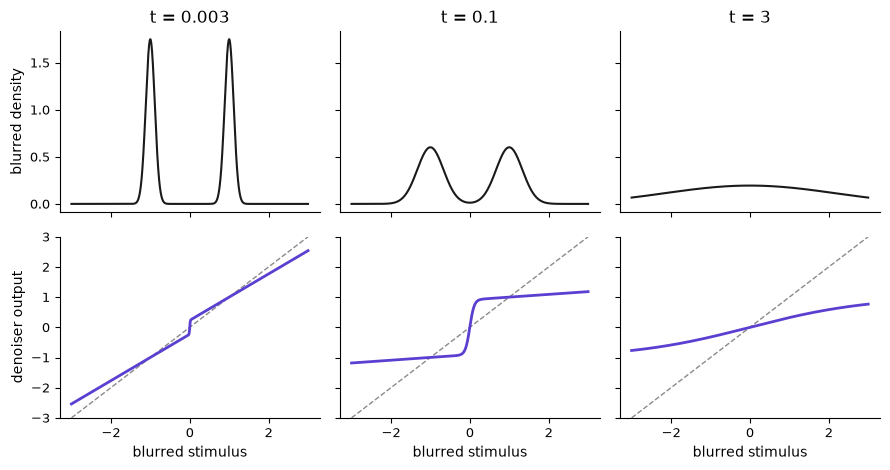

CPU times: user 138 ms, sys: 8.19 ms, total: 146 ms
Wall time: 165 ms


In [9]:
%%time

x_t = torch.linspace(-3, 3, 1201, device=device)
fig, axes = plt.subplots(2, 3, figsize=(9, 4.8), sharex=True, sharey="row")
for col, t in enumerate(SHOWN_T):
    top, bottom = axes[0, col], axes[1, col]
    top.plot(x_t.cpu(), blurred_density(x_t, t).cpu(), color=INK)
    top.set_title(f"t = {t:g}")
    bottom.plot(x_t.cpu(), x_t.cpu(), "--", color=GREY, lw=1)
    bottom.plot(x_t.cpu(), denoiser(x_t, t).cpu(), color=VIOLET, lw=2)
    bottom.set_xlabel("blurred stimulus")
axes[0, 0].set_ylabel("blurred density")
axes[1, 0].set_ylabel("denoiser output")
axes[1, 0].set_ylim(-3, 3)
fig.tight_layout()
plt.show()

At $t = 0.003$ the denoiser follows the observation inside each bump. At $t = 0.1$ it has two flat plateaus near $\pm 1$ joined by a jump at 0: the observation says which bump but no longer where inside it. At $t = 3$ the density has one peak and the denoiser is a gentle S through 0.

## 4. Tweedie's formula

The denoiser has a second expression that needs only the density of the blurred stimulus:

$$\hat{x}(x_t) = x_t + t\, \frac{\partial}{\partial x_t} \ln p_t(x_t).$$

The derivative of $\ln p_t$ is the score of the blurred density. It points to where blurred stimuli are more common, and the denoiser moves the observation by $t$ times the score. The cell computes the score with automatic differentiation of $\ln p_t$ and compares the two expressions of the denoiser, at $x_t = -0.5$ and $t = 0.1$ and then on a whole grid at the three blur levels.

time: <1 sec

In [10]:
%%time


def tweedie_denoiser(x_t, t):
    x_t = x_t.clone().requires_grad_(True)
    (score,) = torch.autograd.grad(blurred_density(x_t, t).log().sum(), x_t)
    return (x_t + t * score).detach(), score


point = torch.tensor([-0.5], device=device)
moved, score_at_point = tweedie_denoiser(point, 0.1)
print(
    f"t = 0.1, x_t = -0.5: score {score_at_point.item():.2f}, x_t + t * score = "
    f"{moved.item():.3f}, posterior mean {denoiser(point, 0.1).item():.3f}"
)

tweedie_gap = max(
    (tweedie_denoiser(x_t, t)[0] - denoiser(x_t, t)).abs().max().item() for t in SHOWN_T
)
print(f"largest difference between the two denoisers on [-3, 3]: {tweedie_gap:.1e}")

t = 0.1, x_t = -0.5: score -4.54, x_t + t * score = -0.954, posterior mean -0.954
largest difference between the two denoisers on [-3, 3]: 7.8e-16
CPU times: user 1.16 ms, sys: 509 μs, total: 1.67 ms
Wall time: 3.61 ms


The score is $-4.5$, and the formula moves the observation by $0.1 \times (-4.5) = -0.45$, to $-0.95$, which is the posterior mean. On the whole grid the two expressions agree to rounding error. A network trained to denoise at blur level $t$ has therefore learned the score of $p_t$.

## 5. Information at each scale

The information that the blurred stimulus carries about the stimulus is the mutual information

$$I(X; X_t) = H(X_t) - H(X_t \mid X),$$

where $H(X_t)$ is the entropy of the blurred density and $H(X_t \mid X) = \tfrac{1}{2}\log_2(2\pi e\, t)$ bits is the entropy of the noise alone. The rate at which it falls with the blur is set by the denoising error (Guo, Shamai and Verdú, 2005):

$$\frac{d\, I(X; X_t)}{dt} = -\frac{\mathrm{MMSE}(t)}{2\,t^2 \ln 2}\ \text{bits per unit of } t.$$

On a logarithmic axis of blur levels, $d \ln t = dt/t$, so the contribution of each scale is $\mathrm{MMSE}(t)/(2\,t \ln 2)$ bits per unit of $\ln t$, and the information at $t$ is the area under this contribution from $t$ to infinity. The cell computes the information from the entropy and the contribution from the denoising error, on 401 blur levels from 0.001 to 100.

time: <1 sec

In [11]:
%%time


def information(t):
    """I(X; X_t) in bits, from the entropy of the blurred density."""
    x_t = stimulus_grid(t)
    p = blurred_density(x_t, t)
    entropy = -torch.trapezoid(p * torch.log2(p.clamp_min(1e-300)), x_t)
    return entropy.item() - 0.5 * math.log2(2 * math.pi * math.e * t)


blur = torch.logspace(-3, 2, 401, device=device)
info = torch.tensor([information(t) for t in blur.tolist()], device=device)
contribution = torch.stack([denoising_error(t) for t in blur.tolist()]) / (
    2 * blur * LN2
)

info_at = {t: information(t) for t in (0.001, 0.01, 0.1, 0.3, 10.0)}
for t, value in info_at.items():
    print(f"I(X; X_t) at t = {t:5}: {value:.2f} bits")

I(X; X_t) at t = 0.001: 2.73 bits
I(X; X_t) at t =  0.01: 1.50 bits
I(X; X_t) at t =   0.1: 1.06 bits
I(X; X_t) at t =   0.3: 0.89 bits
I(X; X_t) at t =  10.0: 0.07 bits
CPU times: user 62.7 ms, sys: 4.35 ms, total: 67 ms
Wall time: 70.7 ms


The information is 2.73, 1.50, 1.06, 0.89 and 0.07 bits at $t = 0.001$, 0.01, 0.1, 0.3 and 10. It falls fast at first, slowly near $t = 0.1$, and fast again between $t = 0.3$ and $t = 10$.

### 5.1. The information is the area of the contribution

The cell checks the integral form at $t = 0.1$, $I(X; X_t) = \frac{1}{2 \ln 2}\int_t^\infty \mathrm{MMSE}(\tau)/\tau^2\, d\tau$, with the integral taken over $\ln \tau$ up to $\tau = 10^4$. It then finds the minimum of the contribution between the two stages and its second maximum.

time: <1 sec

In [12]:
%%time

tail = torch.logspace(-1, 4, 501, device=device)
tail_mmse = torch.stack([denoising_error(t) for t in tail.tolist()])
info_from_mmse = torch.trapezoid(tail_mmse / tail, tail.log()).item() / (2 * LN2)
print(
    f"I at t = 0.1: {info_at[0.1]:.4f} bits from the entropy, "
    f"{info_from_mmse:.4f} bits from the denoising error"
)

middle = (blur > 0.02) & (blur < 0.3)
i_min = torch.where(middle, contribution, torch.inf).argmin()
i_max = torch.where(blur > 0.2, contribution, -torch.inf).argmax()
contribution_min = (blur[i_min].item(), contribution[i_min].item())
contribution_max = (blur[i_max].item(), contribution[i_max].item())
print("minimum of the contribution: %.3f bits at t = %.3f" % contribution_min[::-1])
print("second maximum: %.2f bits at t = %.2f" % contribution_max[::-1])

I at t = 0.1: 1.0635 bits from the entropy, 1.0634 bits from the denoising error
minimum of the contribution: 0.088 bits at t = 0.089
second maximum: 0.35 bits at t = 0.65
CPU times: user 36.9 ms, sys: 2.84 ms, total: 39.7 ms
Wall time: 42.9 ms


The two values of the information agree to 0.0001 bits, the part above $\tau = 10^4$ that the integral leaves out. The contribution has a minimum of 0.088 bits at $t = 0.09$ and a second maximum of 0.35 bits at $t = 0.65$ (0.64 on a finer grid of blur levels, one grid step away). There the blur width is 0.8, close to the distance 1 from each centre to the midpoint between the bumps.

## 6. The bump label and the position inside the bump

Let $B$ be the bump that the stimulus came from. Given $B$, the stimulus is a single Gaussian of variance 0.01, so the information splits exactly into two terms:

$$I(X; X_t) = I(B; X_t) + \tfrac{1}{2}\log_2\!\left(1 + \frac{0.01}{t}\right).$$

The first term is the information about which bump: one fair yes/no question, so it falls from 1 bit to 0. It equals $1 - \mathbb{E}\big[H_2(w_1(x_t))\big]$, where $H_2(w) = -w \log_2 w - (1 - w)\log_2(1 - w)$ is the entropy of a choice with probabilities $w$ and $1 - w$. The second term is the information about the position inside the bump, with contribution $0.01/\big(2 \ln 2\,(t + 0.01)\big)$ per unit of $\ln t$. The cell computes the first term, checks the split and measures the area under the contribution of the first term.

time: <1 sec

In [13]:
%%time


def label_information(t):
    """I(B; X_t) in bits: 1 - E[H2(w(x_t))]."""
    x_t = stimulus_grid(t)
    w = bump_weights(x_t, t)
    h2 = -(w * torch.log2(w.clamp_min(1e-300))).sum(1)
    return 1 - torch.trapezoid(blurred_density(x_t, t) * h2, x_t).item()


label_info_at = {t: label_information(t) for t in (0.1, 0.3, 1.0, 3.0, 10.0)}
print("I(B; X_t):", {t: round(v, 2) for t, v in label_info_at.items()})

within = 0.5 * torch.log2(1 + BUMP_VAR / blur)
label_info = torch.tensor([label_information(t) for t in blur.tolist()], device=device)
split_gap = (label_info + within - info).abs().max().item()
print(f"largest |I(B; X_t) + within-bump term - I(X; X_t)|: {split_gap:.1e} bits")

label_contribution = -torch.gradient(label_info, spacing=(blur.log(),))[0]
within_contribution = BUMP_VAR / (2 * LN2 * (blur + BUMP_VAR))
label_area = label_information(1e-3) - label_information(1e3)
print(f"area of the which-bump contribution, t = 0.001 to 1000: {label_area:.3f} bits")

I(B; X_t): {0.1: 0.99, 0.3: 0.86, 1.0: 0.48, 3.0: 0.21, 10.0: 0.07}
largest |I(B; X_t) + within-bump term - I(X; X_t)|: 1.6e-15 bits
area of the which-bump contribution, t = 0.001 to 1000: 0.999 bits
CPU times: user 40.1 ms, sys: 3.79 ms, total: 43.9 ms
Wall time: 42.9 ms


$I(B; X_t)$ is 0.99, 0.86, 0.48, 0.21 and 0.07 bits at $t = 0.1$, 0.3, 1, 3 and 10, the split holds to rounding error, and the area of the which-bump contribution is 1 bit.

### 6.1. Figure: information at each scale

Top: the information $I(X; X_t)$ against the blur level, with 1 bit dashed. Bottom: the contribution of each scale (ink), split into the position inside the bump (grey) and the bump label (violet).

time: <1 sec

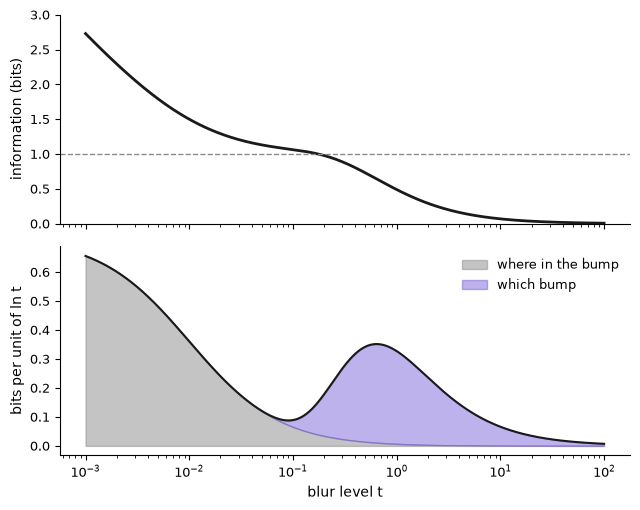

CPU times: user 212 ms, sys: 7.15 ms, total: 219 ms
Wall time: 227 ms


In [14]:
%%time

fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.5, 5.2), sharex=True)
b = blur.cpu()
top.plot(b, info.cpu(), color=INK, lw=2)
top.axhline(1.0, ls="--", color=GREY, lw=1)
top.set_ylabel("information (bits)")
top.set_ylim(0, 3)

bottom.fill_between(
    b, 0, within_contribution.cpu(), color=GREY, alpha=0.5, label="where in the bump"
)
bottom.fill_between(
    b,
    within_contribution.cpu(),
    (within_contribution + label_contribution).cpu(),
    color=VIOLET,
    alpha=0.4,
    label="which bump",
)
bottom.plot(b, contribution.cpu(), color=INK, lw=1.5)
bottom.set_xscale("log")
bottom.set_xlabel("blur level t")
bottom.set_ylabel("bits per unit of ln t")
bottom.legend(loc="upper right")
fig.tight_layout()
plt.show()

The information falls in two stages. It falls fast while the position inside a bump is lost, which ends near $t = 0.1$, stays close to 1 bit there, and then falls again between $t = 0.1$ and $t = 10$, where the bump label is lost. The contribution of the position inside a bump approaches $1/(2 \ln 2) = 0.72$ bits per unit of $\ln t$ at small $t$, so its area is infinite: a continuous stimulus holds more bits the finer the scale at which it is seen.

## 7. Try it

1. Move the bumps apart, for example `CENTRES = torch.tensor([-3.0, 3.0])`, and rerun the notebook. The violet area stays 1 bit and moves to larger blur levels, by a factor 9 in $t$.
2. Give the bumps unequal weights, 0.9 and 0.1 (change the factor 0.5 in `blurred_density` and add the log-weights in `bump_weights`). The which-bump area becomes the entropy of the label, 0.47 bits.
3. Replace the prior by a single Gaussian of variance $s^2$ and check that the information is $\tfrac{1}{2}\log_2(1 + s^2/t)$.

The cell carries out the first change with the functions of the notebook and prints where the which-bump contribution is largest.

time: <1 sec

In [15]:
%%time

CENTRES = torch.tensor([-3.0, 3.0], device=device)  # bumps 6 apart instead of 2

wide_label = torch.tensor([label_information(t) for t in blur.tolist()], device=device)
wide_contribution = -torch.gradient(wide_label, spacing=(blur.log(),))[0]
wide_peak = blur[wide_contribution.argmax()].item()
wide_area = label_information(1e-3) - label_information(1e3)
print(
    f"bumps 6 apart: which-bump area {wide_area:.3f} bits, largest at t = "
    f"{wide_peak:.1f}"
)
print(f"bumps 2 apart: largest at t = {blur[label_contribution.argmax()].item():.2f}")

CENTRES = torch.tensor([-1.0, 1.0], device=device)  # back to the bumps of the notebook

bumps 6 apart: which-bump area 0.994 bits, largest at t = 6.0
bumps 2 apart: largest at t = 0.67
CPU times: user 49.6 ms, sys: 5.93 ms, total: 55.5 ms
Wall time: 72.3 ms


The which-bump bit keeps its area of 1 bit, of which 0.994 bits are lost between $t = 0.001$ and $t = 1000$. The bit is lost about nine times later in $t$, or three times later in blur width, the factor by which the distance between the bumps grew.